# M4: Classification error analysis

Compare the saved **0% synthetic (real-only)** and **25% synthetic** DistilBERT checkpoints on the same original 7,600-article AG News test split. The 25% checkpoint had the highest test macro F1 among the five M3 mixtures. This choice was made after inspecting test scores, so the comparison is exploratory and its small lead should not be treated as an unbiased model-selection estimate. Both checkpoints use one epoch, seed 42, learning rate 5e-5, weight decay 0.01, and the same architecture. GPU inference is performed once by `python src/analyze_errors.py`; this notebook reads the saved paired predictions.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'results' / 'error_analysis'
pred = pd.read_csv(OUT / 'paired_predictions.csv')
examples = pd.read_csv(OUT / 'representative_errors.csv')
summary = json.loads((OUT / 'summary.json').read_text(encoding='utf-8'))
assert len(pred) == 7600 and len(examples) >= 10

## Overall paired outcomes

A fix means the baseline was wrong and the synthetic model was correct. A new error means the reverse. Each row is the *same test article*, so these counts expose what changed beyond aggregate accuracy.

In [2]:
display(pd.DataFrame({'count': pred.outcome.value_counts(), 'share': pred.outcome.value_counts(normalize=True)}).round(4))
print('Real-only accuracy:', round(summary['accuracy']['real_only'], 4))
print('25% synthetic accuracy:', round(summary['accuracy']['synthetic_25'], 4))
print('Net additional correct:', summary['outcomes']['synthetic_fixes'] - summary['outcomes']['synthetic_new_error'])

,count,share
outcome,,
both_correct,6762,0.8897
both_wrong,559,0.0736
synthetic_fixes,144,0.0189
synthetic_new_error,135,0.0178


Real-only accuracy: 0.9075
25% synthetic accuracy: 0.9087
Net additional correct: 9


## Category-level errors and confusions

Rows are true labels; columns are predictions. The difference matrix is synthetic minus real-only. Positive diagonal values mean more correct predictions; positive off-diagonal values mean more mistakes of that type.

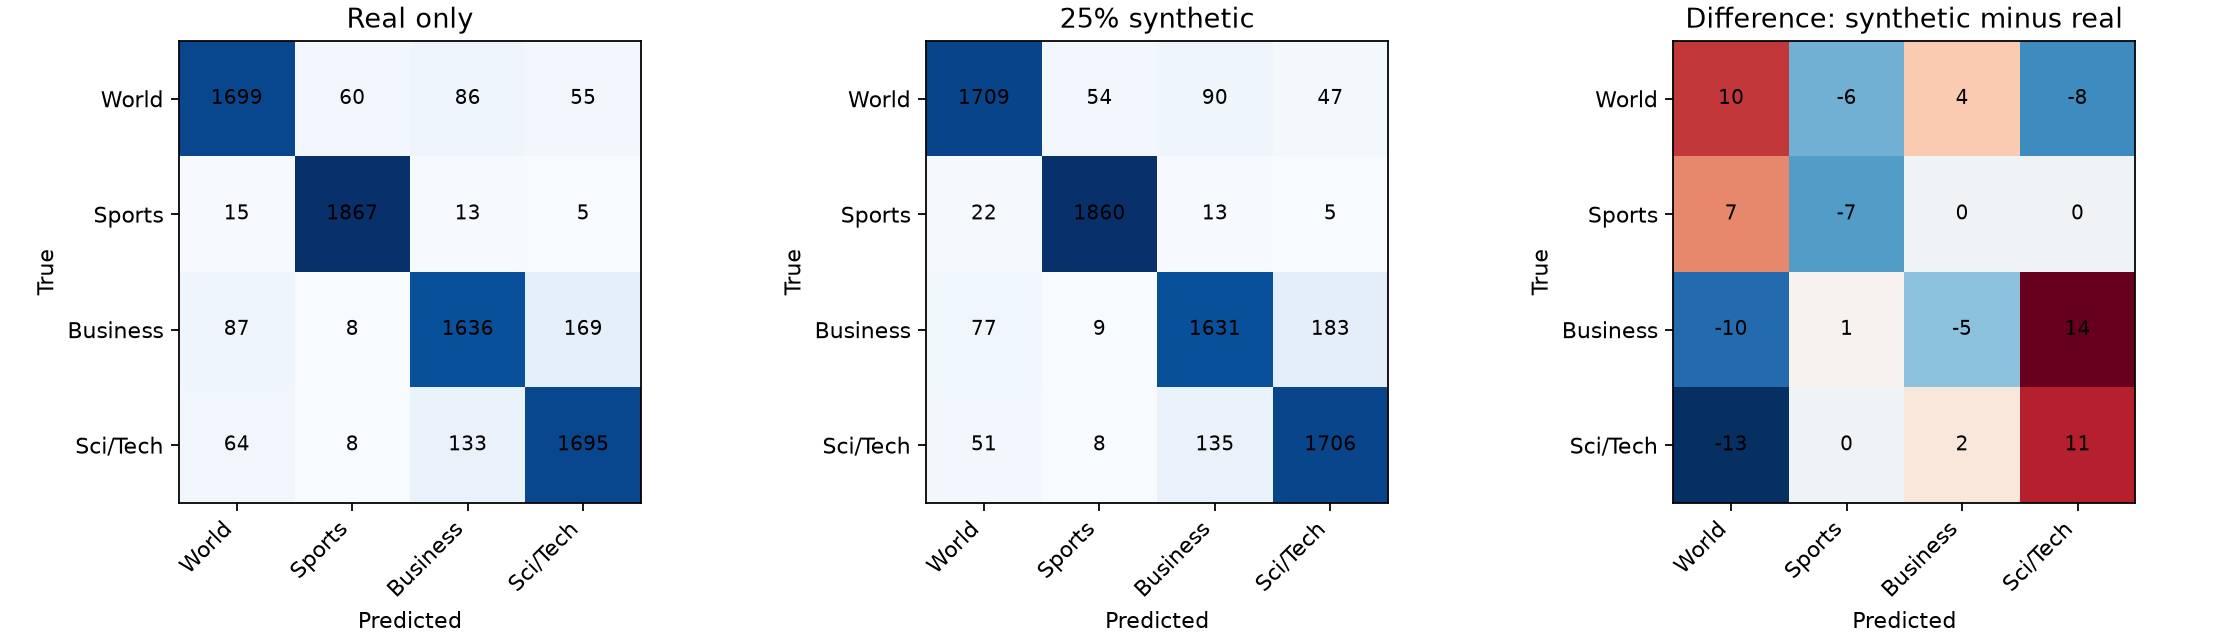

,true_category,real_only_accuracy,synthetic_25_accuracy,difference
0,Business,0.8611,0.8584,-0.0026
1,Sci/Tech,0.8921,0.8979,0.0058
2,Sports,0.9826,0.9789,-0.0037
3,World,0.8942,0.8995,0.0053



 real_only most frequent confusions


,true_category,real_only_category,count
0,Business,Sci/Tech,169
1,Sci/Tech,Business,133
2,Business,World,87
3,World,Business,86
4,Sci/Tech,World,64
5,World,Sports,60
6,World,Sci/Tech,55
7,Sports,World,15



 synthetic_25 most frequent confusions


,true_category,synthetic_25_category,count
0,Business,Sci/Tech,183
1,Sci/Tech,Business,135
2,World,Business,90
3,Business,World,77
4,World,Sports,54
5,Sci/Tech,World,51
6,World,Sci/Tech,47
7,Sports,World,22


In [3]:
display(Image(filename=str(OUT / 'confusion_comparison.png')))
display(pd.read_csv(OUT / 'per_class.csv').round(4))
for name in ['real_only', 'synthetic_25']:
    wrong = pred[~pred[f'{name}_correct']]
    print('\n', name, 'most frequent confusions')
    display(wrong.groupby(['true_category', f'{name}_category']).size().sort_values(ascending=False).head(8).rename('count').reset_index())

## Representative articles

The table contains **5 new errors, 5 fixes, and 4 errors shared by both models**. Selection is deterministic and spans categories where possible. Full article text and test indices are retained in `representative_errors.csv`; the display shortens text for readability. These examples illustrate mechanisms, not their population frequency.

In [4]:
view = examples[['test_index','outcome','true_category','real_only_category','synthetic_25_category','real_only_confidence','synthetic_25_confidence','text']].copy()
view['text'] = view['text'].str.slice(0, 320)
display(view.round(3))

,test_index,outcome,true_category,real_only_category,synthetic_25_category,real_only_confidence,synthetic_25_confidence,text
0,5588,synthetic_new_error,World,World,Business,0.657,0.516,China's inflation rate slows sharply but probl...
1,5024,synthetic_new_error,Sports,Sports,World,0.799,0.427,FleetCenter to be reunion arena It has all the...
2,1273,synthetic_new_error,Business,Business,World,0.586,0.371,"Summer Box Office Hits a High, Despite Lows In..."
3,7440,synthetic_new_error,Sci/Tech,Sci/Tech,World,0.448,0.358,A Distraction as a Deadline Approaches As the ...
4,6248,synthetic_new_error,Business,Business,World,0.599,0.411,Study Ranks St. Louis as Fourth Most Dangerous...
5,5928,synthetic_fixes,World,Business,World,0.652,0.458,Smoking ban would target pubs ritain #39;s gov...
6,952,synthetic_fixes,Sports,Business,Sports,0.515,0.689,Athens coverage a winner for NBC NBC and its f...
7,7598,synthetic_fixes,Business,World,Business,0.771,0.353,5 of arthritis patients in Singapore take Bext...
8,1035,synthetic_fixes,Sci/Tech,World,Sci/Tech,0.675,0.467,Europeans Eat Less of Dangerous Fatty Foods By...
9,3916,synthetic_fixes,World,Sci/Tech,World,0.875,0.466,Kerry to reverse stem cell policy US president...


### What the examples suggest

- **Topic boundaries are ambiguous.** Test article 1273 discusses box-office results and is labeled Business, while the synthetic model predicts World. Article 3916 mixes election policy and stem-cell research; the synthetic model corrects a baseline Sci/Tech prediction to World.
- **Context can outweigh the headline.** Article 952 concerns TV coverage of the Olympics: the baseline predicts Business and the synthetic model predicts Sports. Article 5024 has a venue/reunion headline and moves the other way, from a correct Sports prediction to World.
- **Some labels may be debatable from the short visible text.** Article 7440 is labeled Sci/Tech although the excerpt mentions holiday bargain hunting; it is included as an observed new error, not proof that the model learned the wrong concept. The full text should be read before assigning a cause.
- **Both models can fail on unusual wording.** Article 481 uses metaphorical language about a business takeover; the baseline predicts Sci/Tech and the synthetic model predicts World instead of Business.

These observations are hypotheses about individual predictions. They do not establish that synthetic data itself caused a particular semantic shift.

## Confidence and difficult predictions

Confidence here is the largest softmax probability. It is a ranking signal, not a calibrated probability of correctness.

In [5]:
rows = []
for name in ['real_only','synthetic_25']:
    wrong = pred[~pred[f'{name}_correct']]
    rows.append({'model':name,'incorrect':len(wrong),'incorrect_confidence_below_0_5':int((wrong[f'{name}_confidence']<0.5).sum()),'incorrect_confidence_at_least_0_9':int((wrong[f'{name}_confidence']>=0.9).sum()),'mean_incorrect_confidence':wrong[f'{name}_confidence'].mean()})
display(pd.DataFrame(rows).round(4))
low = pred[(~pred.synthetic_25_correct) & (pred.synthetic_25_confidence < 0.5)]
display(low.nsmallest(8, 'synthetic_25_confidence')[['test_index','true_category','synthetic_25_category','synthetic_25_confidence','text']].assign(text=lambda d:d.text.str.slice(0,220)).round(3))

,model,incorrect,incorrect_confidence_below_0_5,incorrect_confidence_at_least_0_9,mean_incorrect_confidence
0,real_only,703,50,246,0.7748
1,synthetic_25,694,24,332,0.8279


,test_index,true_category,synthetic_25_category,synthetic_25_confidence,text
7440,7440,Sci/Tech,World,0.358,A Distraction as a Deadline Approaches As the ...
1273,1273,Business,World,0.371,"Summer Box Office Hits a High, Despite Lows In..."
6248,6248,Business,World,0.411,Study Ranks St. Louis as Fourth Most Dangerous...
5024,5024,Sports,World,0.427,FleetCenter to be reunion arena It has all the...
6037,6037,Business,World,0.429,Stern Blasts FCC at Satellite Promotion #39;D...
6380,6380,Business,Sci/Tech,0.430,FBI Interviews Halliburton Whistleblower Bunna...
5222,5222,Business,World,0.435,Bridges Loom as Cash Cow That Nobody Dares to ...
4958,4958,Sci/Tech,Business,0.436,London Times goes strictly tabloid After more ...


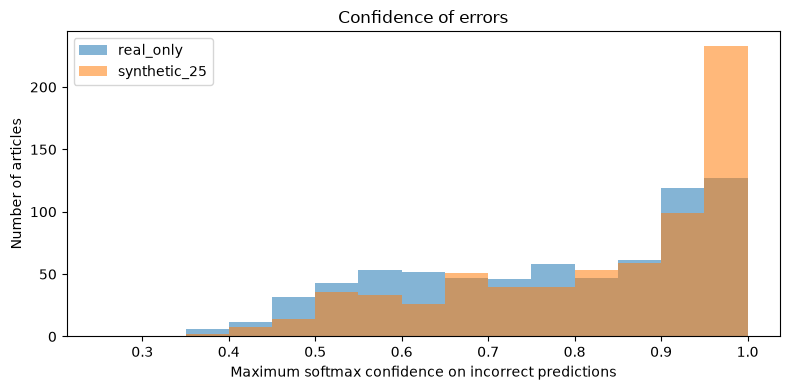

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in ['real_only','synthetic_25']:
    ax.hist(pred.loc[~pred[f'{name}_correct'],f'{name}_confidence'],bins=np.linspace(0.25,1,16),alpha=.55,label=name)
ax.set(xlabel='Maximum softmax confidence on incorrect predictions',ylabel='Number of articles',title='Confidence of errors')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'error_confidence.png',dpi=160); display(fig); plt.close(fig)

## Limitations

The 25% model gains only nine net correct predictions: 144 fixes and 135 new errors. World and Sci/Tech recall improve slightly while Sports and Business recall fall slightly. The frequent Business–Sci/Tech confusion remains in both models, consistent with articles about technology companies or technical products that also have a financial angle. The models were trained with one seed and one epoch, and some test articles have short or noisy text. Softmax confidence is uncalibrated. The selected synthetic mixture was chosen using these test scores, and individual example interpretations are qualitative; repeat with held-out selection data and multiple seeds before claiming a robust gain.